<h1><center>Data Analysis and Simulation</center></h1>
<h3><center>Working notebook</center></h3>

## Imports

In [20]:
# Matplotlib setup, could be swapped for pyqt (realtime) or data shader(large datasets)
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

# Dependencies
import astropy.constants as c
import astropy.units as u
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
from astropy.time import Time
import glob
import numpy as np
import os
import h5py
from rich.progress import track
import scipy
from scipy import ndimage
from scipy.signal import medfilt
from scipy.signal import welch
from scipy.signal import csd
from scipy.signal.windows import blackmanharris
from scipy.spatial.distance import pdist

## Parameter Initilization 

In [2]:
# Define key interferometer parameters
#TODO should be all caps
central_freq = 1418*u.MHz
#TODO should this be renamed bandwidth?
nbins = 2**15
samp_rate = 16e6*u.Hz
dt = 1/samp_rate
SUBBANDS_OFFSET = 430

# Algo control params
#TODO Should be all caps
simulate_antennas = True # toggle artificial antennas generation here
simulate_times = True # toggle the addition of artificially derived observations 30 min apart
FOLDER_NOMENCLATURE = 'data_*'
FILE_NOMENCLATURE = 'init_data_*'


## Antenna Config #

Physical setup 

In [3]:
# Define antenna positions in local coordinates (x, y, z) in meters
# First default position
if simulate_antennas:
    # add imaginary antennas as desired
    posx = [0, 1, 2, 3, 4, 0, 1, 2, 3]
    posy = [0, 0, 0, 0, 2, 2, 3, 3, 4]
    posz = [0, 0, 0, 0, 0, 0, 0, 0, 0]
    n_real_ant = 2
else:
    # define only real antennas from which we have data
    posx = [0, 1]
    posy = [0, 0]
    posz = [0, 0]
    n_real_ant = len(posx)

# Second default position
post = [] #radians
posr = [] #meters
posp = [] #radians

# Observation coordinates and time(s)
lat = 52.167*u.deg
lon = 4.461*u.deg
height = 1*u.m
leiden = EarthLocation(lat=lat, lon=lon, height=height)
obs_times = [Time('2026-10-30 16:30:00')]
n_real_obs = len(obs_times)
if simulate_times:
    for i in range(2):
        obs_times.append(obs_times[-1] + 30*u.min)
az = 0.1 * u.deg
alt = 89 * u.deg
altaz_frames = [AltAz(obstime=obs_times[i], location=leiden) for i in range(len(obs_times))]
altaz_coords = [SkyCoord(alt=alt, az=az, frame=altaz_frames[i]) for i in range(len(altaz_frames))]
radec_coords = [coord.transform_to('icrs') for coord in altaz_coords]
hour_angles = (Time(obs_times) - obs_times[0]).to(u.hour).value * 15

# assemble position array and derive important properties
pos = np.array([posx, posy, posz]).T*u.m
num_antennas = pos.shape[0]
largest_baseline = np.max(pdist(pos)) * u.m
print(f"Array comprised of {num_antennas} antennas with a largest baseline of {largest_baseline:.2f} and data from {len(obs_times)} distinct times")

Array comprised of 9 antennas with a largest baseline of 5.00 m and data from 3 distinct times


UV plane

In [4]:
# compute uv coordinate array and plot uv coverage
# def compute_uv_coordinates(ant_pos, dtype=np.float32):
#     num_ant = len(ant_pos)
#     u_ant = ant_pos[:,0]
#     v_ant = ant_pos[:,1]
#     result = np.zeros((num_ant, num_ant, 2), dtype=dtype)*u.m
#     for ant1 in range(num_ant):
#         for ant2 in range(num_ant):
#             result[ant1, ant2, 0] = u_ant[ant2] - u_ant[ant1]
#             result[ant1, ant2, 1] = v_ant[ant2] - v_ant[ant1]
#     return result

def compute_uv_coordinates(ant_pos, hour_angles, lat_deg, dtype=np.float32):
  num_ant = len(ant_pos)
  num_times = len(hour_angles)

  lat_rad = np.radians(lat_deg)
  hour_angles_rad = np.radians(hour_angles)

  east = ant_pos[:, 0]
  north = ant_pos[:, 1]
  el = ant_pos[:, 2]

  du = east[np.newaxis, :] - east[:, np.newaxis]
  dv = north[np.newaxis, :] - north[:, np.newaxis]
  dw = el[np.newaxis, :] - el[:, np.newaxis]

  result = np.zeros((num_times, num_ant, num_ant, 3), dtype=dtype)

  for t_idx, h in enumerate(hour_angles_rad):
    sin_h = np.sin(h)
    cos_h = np.cos(h)
    sin_lat = np.sin(lat_rad)
    cos_lat = np.cos(lat_rad)

    u_time = sin_h*dv + cos_h*du
    v_time = -sin_lat*cos_h*dv + sin_lat * sin_h * du + cos_lat*dw
    w_time = cos_lat*cos_h*dv - cos_lat*sin_h*du + sin_lat*dw

    result[t_idx, :, :, 0] = u_time
    result[t_idx, :, :, 1] = v_time
    result[t_idx, :, :, 2] = w_time

  return result

uv = compute_uv_coordinates(pos, hour_angles, lat)*u.m
uvwl = (uv*central_freq/c.c).decompose()

Visualization

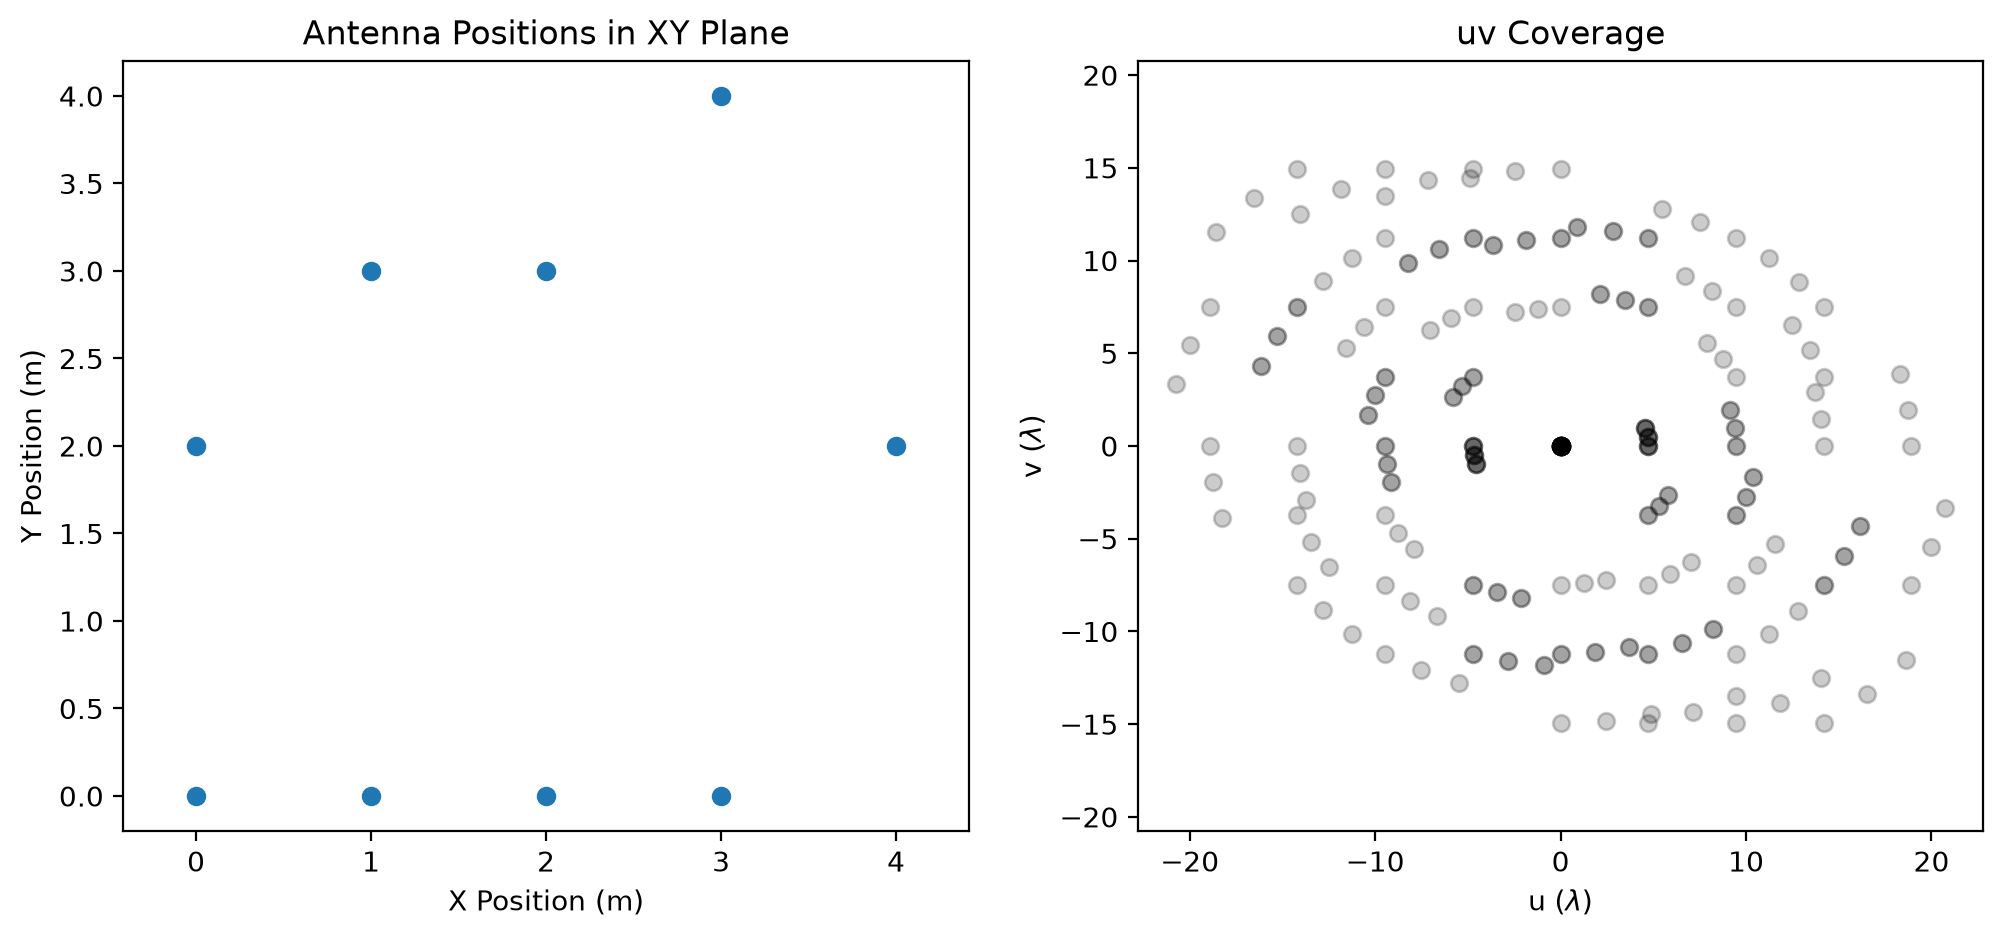

In [5]:
# plot antenna configuration in local coordinates
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(pos[:, 0], pos[:, 1])
ax[0].set_xlabel('X Position (m)')
ax[0].set_ylabel('Y Position (m)')
ax[0].set_title('Antenna Positions in XY Plane')
ax[0].axis('equal')

ax[1].scatter(uvwl[:, :,:,0], uvwl[:, :,:,1], c='black', alpha=0.2)
ax[1].set_xlabel(r'u ($\lambda$)')
ax[1].set_ylabel(r'v ($\lambda$)')
ax[1].set_title('uv Coverage')
ax[1].axis('equal')

# Stop the printing the array
_ = 0


## Load the data

Set the folder

In [6]:
CWD = os.getcwd()
OBS_FOLDER = os.path.join(CWD, 'observations')

files = glob.glob(os.path.join(OBS_FOLDER, FOLDER_NOMENCLATURE, FILE_NOMENCLATURE))

Truncate the data to uniformity

In [7]:
raw_data = [np.fromfile(file, dtype=np.complex64) for file in track(files, description="Loading data")]

# Assuming all data starts with the same time (sync team)
# Truncate data to the same length (compatible with nbins) for all antennas
minlen = min(len(data) for data in raw_data)
nblocks = int((minlen // 10) // nbins)  # divide minlen to reduce data size even further for saving resources during testing
truncation_index = int(nblocks * nbins)
truncated_data = np.array([data[:truncation_index] for data in raw_data])
data_array = np.zeros((len(obs_times), num_antennas, truncation_index))
data_array[:n_real_obs, :n_real_ant] = truncated_data.reshape(n_real_obs, n_real_ant, truncation_index)

# generate articifial phase shifted data for imaginary antennas and times
if simulate_times:
    freq = np.sort(np.fft.fftfreq(nbins, 1/(samp_rate))) + central_freq
    simfreqs = np.tile(freq, nblocks)
    for i in range(n_real_obs, len(obs_times)):
        ra = radec_coords[i].ra.deg
        dec = radec_coords[i].dec.deg
        s = np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])
        for k in range(n_real_ant):
            b = uv[i, 0, k, :] - uv[i-1, 0, k, :]
            tau = np.dot(b, s)/c.c
            phase_shift = np.exp(-2j * np.pi * simfreqs * tau)
            data_array[i, k] = data_array[i-1, k]*phase_shift
if simulate_antennas:
    freq = np.sort(np.fft.fftfreq(nbins, 1/(samp_rate))) + central_freq
    simfreqs = np.tile(freq, nblocks)
    for i in range(len(obs_times)):
        ra = radec_coords[i].ra.deg
        dec = radec_coords[i].dec.deg
        s = np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])
        for k in range(n_real_ant, num_antennas):
            b = pos[k]
            tau = np.dot(b, s)/c.c
            phase_shift = np.exp(-2j * np.pi * simfreqs * tau)
            data_array[i, k] = data_array[i, 0]*phase_shift

print(f"Data for {num_antennas} antennas extracted.")
print(f"{truncation_index} data points from each antenna.")


Output()

/tmp/ipykernel_76804/1440941341.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  data_array[:n_real_obs, :n_real_ant] = truncated_data.reshape(n_real_obs, n_real_ant, truncation_index)
/tmp/ipykernel_76804/1440941341.py:24: ComplexWarning: Casting complex values to real discards the imaginary part
  data_array[i, k] = data_array[i-1, k]*phase_shift
/tmp/ipykernel_76804/1440941341.py:36: ComplexWarning: Casting complex values to real discards the imaginary part
  data_array[i, k] = data_array[i, 0]*phase_shift


Data for 9 antennas extracted.
16121856 data points from each antenna.


Visualize

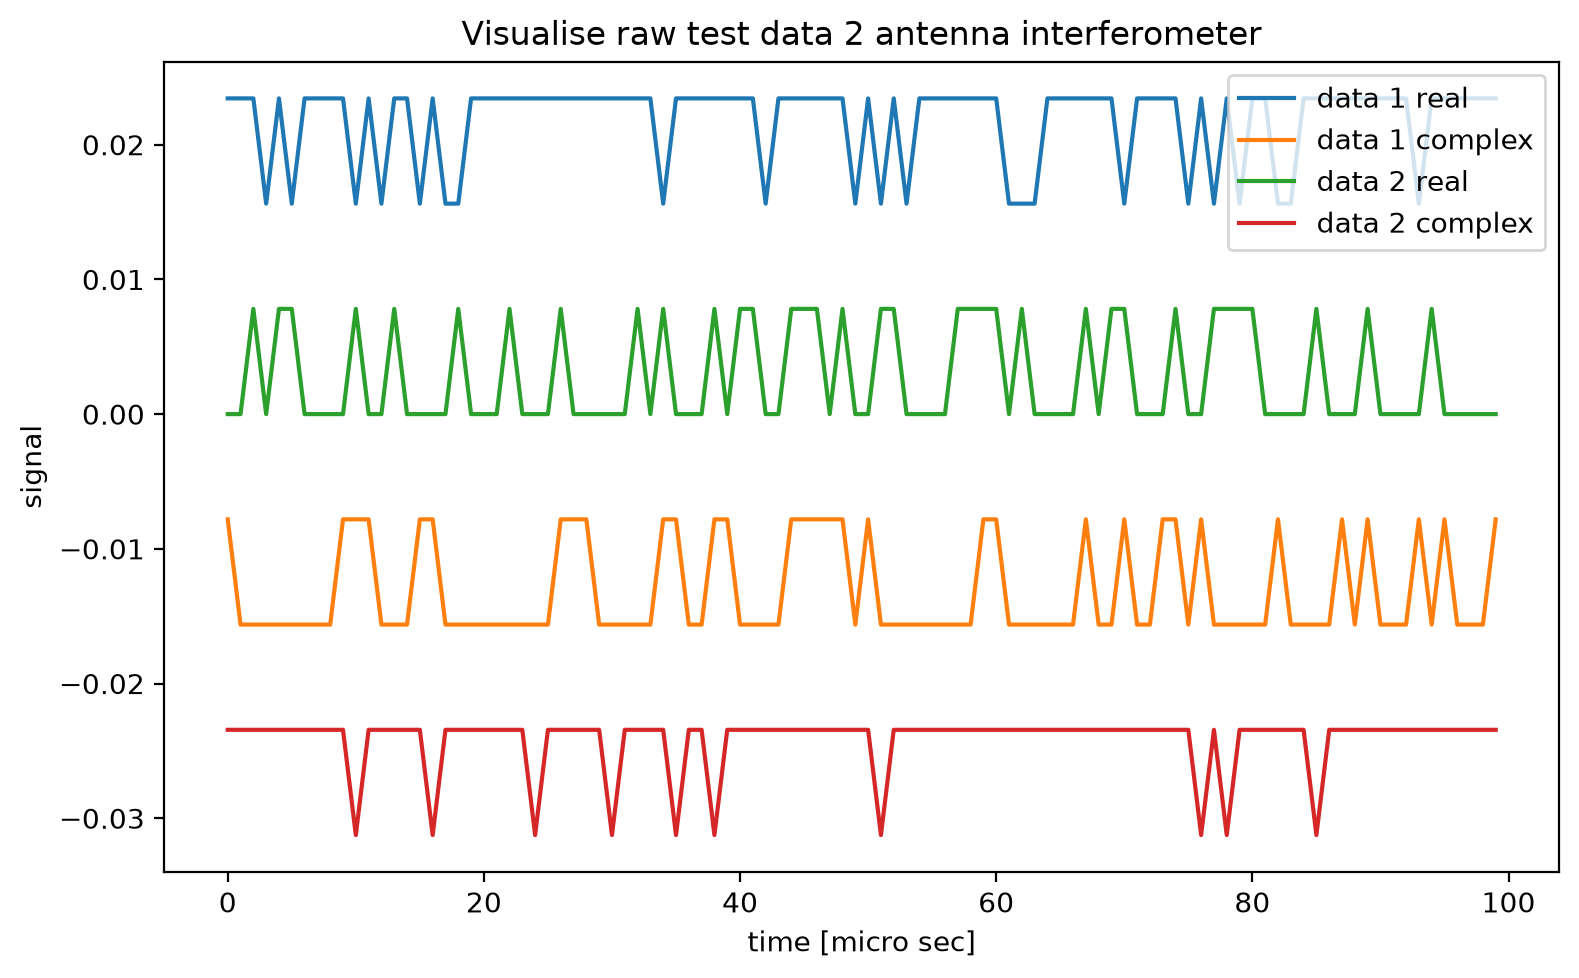

In [8]:
# visualise cut out of raw data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Visualise raw test data 2 antenna interferometer')
ax.plot(np.real(raw_data[0][0:100]), label = 'data 1 real')
ax.plot(np.imag(raw_data[0][0:100]), label = 'data 1 complex')
ax.plot(np.real(raw_data[1][0:100]), label = 'data 2 real')
ax.plot(np.imag(raw_data[1][0:100]), label = 'data 2 complex')
ax.set_xlabel("time [micro sec]")
ax.set_ylabel('signal')
ax.legend()
fig.tight_layout()
plt.show()

## Calculate FFT of the antennas

In [9]:
subband = (nbins // 2) + SUBBANDS_OFFSET # look at an offset of subbands after the center

window = blackmanharris(nbins)
freq = np.zeros(truncation_index)
fft_data = np.zeros((len(obs_times), num_antennas, nbins), dtype='complex64')

# Calculate FFTs
for k in track(range(len(obs_times)), description='Iterating through observations'):
    for i in track(range(num_antennas), description="Computing FFTs for each antenna"):
        df = data_array[k, i, :]
        df = df - np.mean(df) # Remove DC offset 
        frequency, fft_output = welch(df, fs=samp_rate, window=window, nperseg=nbins, return_onesided=False)
        freq = np.fft.fftshift(frequency) + central_freq.to(u.Hz)
        fft_data[k, i] = np.fft.fftshift(fft_output)


Output()

Computing FFTs for each antenna ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:22

Computing FFTs for each antenna ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:07

Computing FFTs for each antenna ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:06

visualize the ffts

/home/dorian/PythonRA314/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/dorian/PythonRA314/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


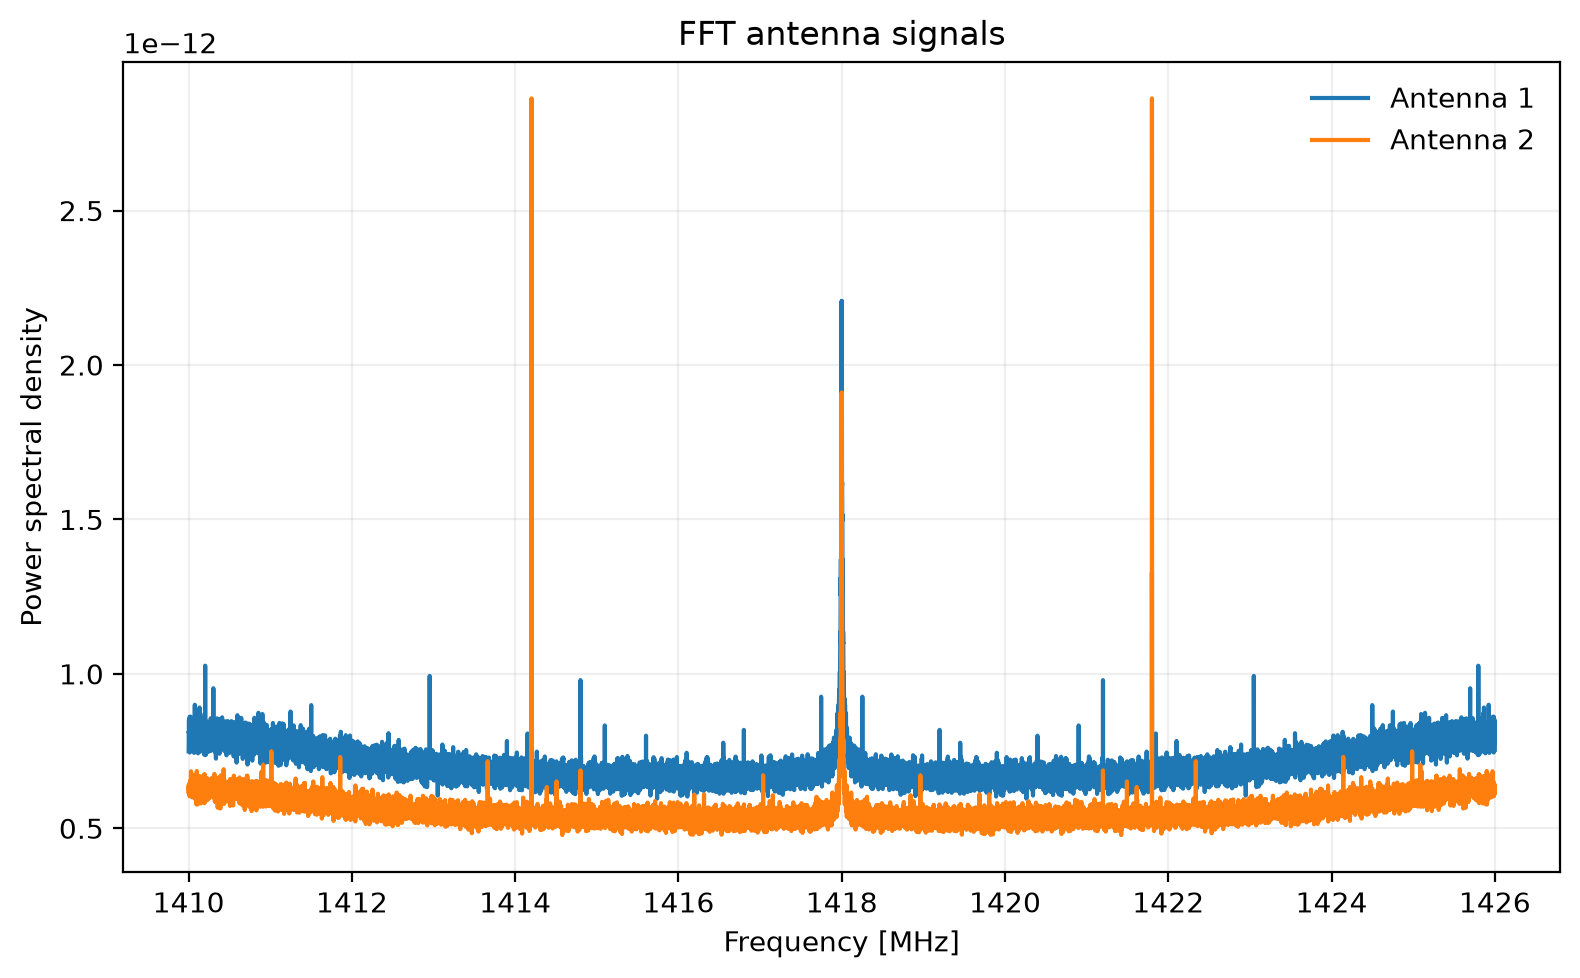

In [10]:
# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
ax.plot(freq / 1e6, fft_data[0, 0], label='Antenna 1')
ax.plot(freq / 1e6, fft_data[0, 1], label='Antenna 2')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### plot the shifted cross correlated spectra to check for time delays

In [11]:
# # correlate the signal
# n_shifts = 100

# correlations = np.zeros(n_shifts)
# time_delays = np.zeros(n_shifts)

# for i in range(n_shifts):
#     antenna2 = fft_data[1]
    
#     # Shift antenna 2 from -50 to +50 datapoints
#     shifted_a2 = np.roll(antenna2, i-50)

#     # cross correlate the two spectra
#     cross_spectrum = fft_data[0] * np.conj(shifted_a2)
    
#     # Calculate correlation coefficient
#     correlations[i] = np.sum(cross_spectrum)

#     # Convert sample shift to time delay (dt per data point)
#     time_delays[i] = i * dt - (50*dt)

# # Find maximum correlation
# max_index = np.argmax(np.abs(correlations))

# print('Maximum correlation:', correlations[max_index])
# print('Time delay:', time_delays[max_index], 'seconds')
# print('Sample shift:', max_index)

# # visualise time delayed cross correlation
# fig, ax = plt.subplots(figsize=(8, 5))
# ax.set_title('Signal cross-correlation')
# ax.plot(time_delays * 1e9, correlations)
# ax.set_xlabel('Time delay (ns)')
# ax.set_ylabel('cross-correlated signal')
# ax.grid(alpha=0.2)
# fig.tight_layout()
# plt.show()

### Compute ACM cube
calculate subband visibilities (cross-correlations) and add them to a data cube

In [12]:
acm = np.zeros((len(obs_times), num_antennas, num_antennas), dtype='complex64')
for i in track(range(len(obs_times)), description='Iterating through observations'):
    for ant1 in track(range(num_antennas), description="Assembling ACM"):
        for ant2 in range(num_antennas):
            # calculate the cross correlated spectra
            # cross_corr = fft_data[ant1] * np.conj(fft_data[ant2])
            freq, cross_corr = csd(data_array[i, ant1, :], data_array[i, ant2, :], fs=samp_rate, nperseg=nbins, return_onesided=False)
            # the visibility is the cross correlation of each subband
            acm[i, ant1, ant2] = cross_corr[subband]
print("ACM generated succesfully!")

Output()

Assembling ACM ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:01:57

Assembling ACM ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:01:51

Assembling ACM ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:01:58

ACM generated succesfully!


### Create image of ACM cube

In [13]:
# Helper functions for generating images
def pixel_brightness(acm_single_pol, l, m, uv, frequency):
    a = acm_single_pol.astype(np.complex64)
    n = a.shape[0]
    uv_l = uv.astype(np.float32)
    uv_l = (uv_l * frequency/c.c).decompose()
    ll = l.to(u.rad).value
    mm = m.to(u.rad).value
    mask = np.ones((n, n), dtype=np.float32)
    mask -= np.diag(np.ones(n, dtype=np.float32)) # remove auto-correlations
    num_vis = mask.sum()
    brightness = (a*mask*np.exp(2j*np.pi*(uv_l[...,0]*ll + uv_l[...,1]*mm))).real.sum()
    return brightness/num_vis

def subband_frequency(subband_number, clock_frequency=20*u.MHz):
    return (subband_number/nbins)*clock_frequency + (central_freq - clock_frequency/2)

def make_image(acm, num_pix, uv, frequency, l_range=(1.0, -1.0), m_range=(-1.0, 1.0)):
    img = np.zeros((num_pix, num_pix), dtype=np.float32)
    l_coor = np.linspace(*l_range, num_pix)*u.rad
    m_coor = np.linspace(*m_range, num_pix)*u.rad

    for m_ix, m in enumerate(track(m_coor, description="Generating image")):
        for l_ix, l in enumerate(l_coor):
            img[m_ix, l_ix] = pixel_brightness(acm, l, m, uv, frequency)
    pixel_sep = m_coor[1]-m_coor[0]
    half = pixel_sep.to(u.rad).value/2.0
    img_extent =(l_coor[0].to(u.rad).value-half, m_coor[0].to(u.rad).value+half, 
                 l_coor[-1].to(u.rad).value+half, m_coor[-1].to(u.rad).value-half)    
    return img, img_extent

Output()

Number of pixels should be 118


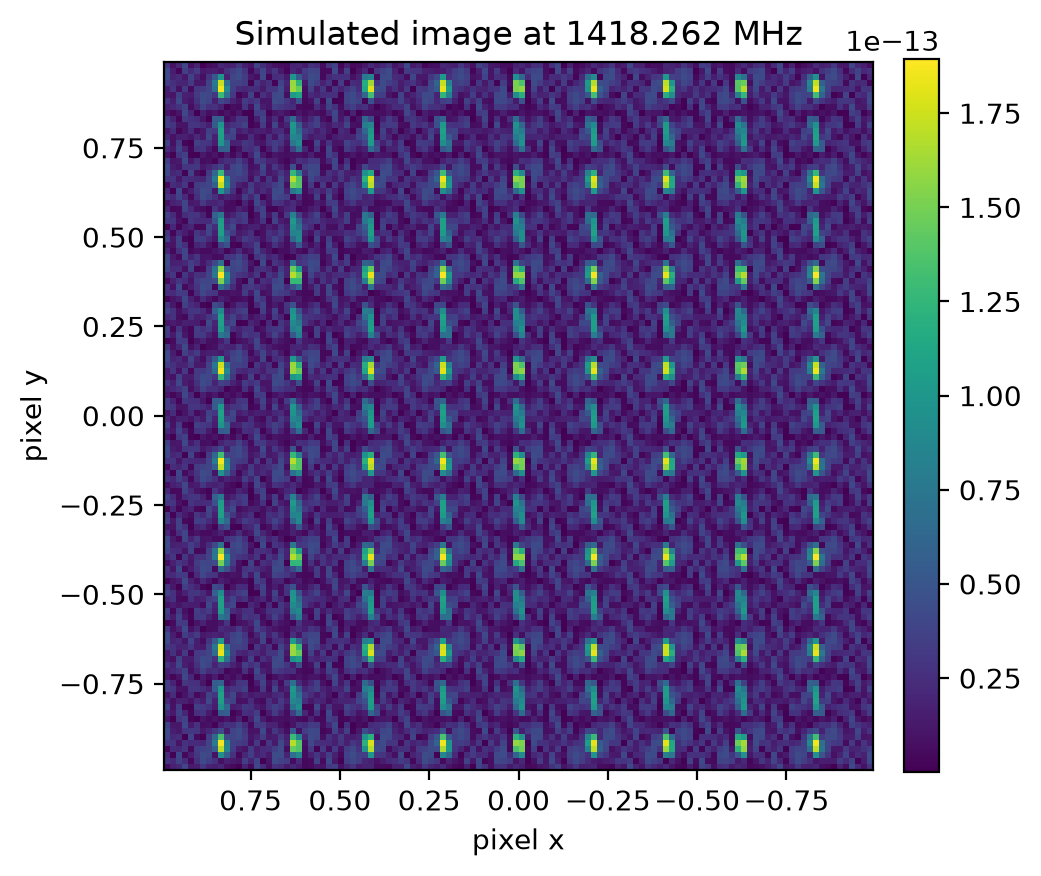

In [14]:
# Make and plot image
f = subband_frequency(subband)
fwhm =  ((c.c/f)/(largest_baseline)).decompose()*u.rad
num_pix = int(2*u.rad / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

obs_num = 0

img, extent = make_image(acm[obs_num, :, :], num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


Output()

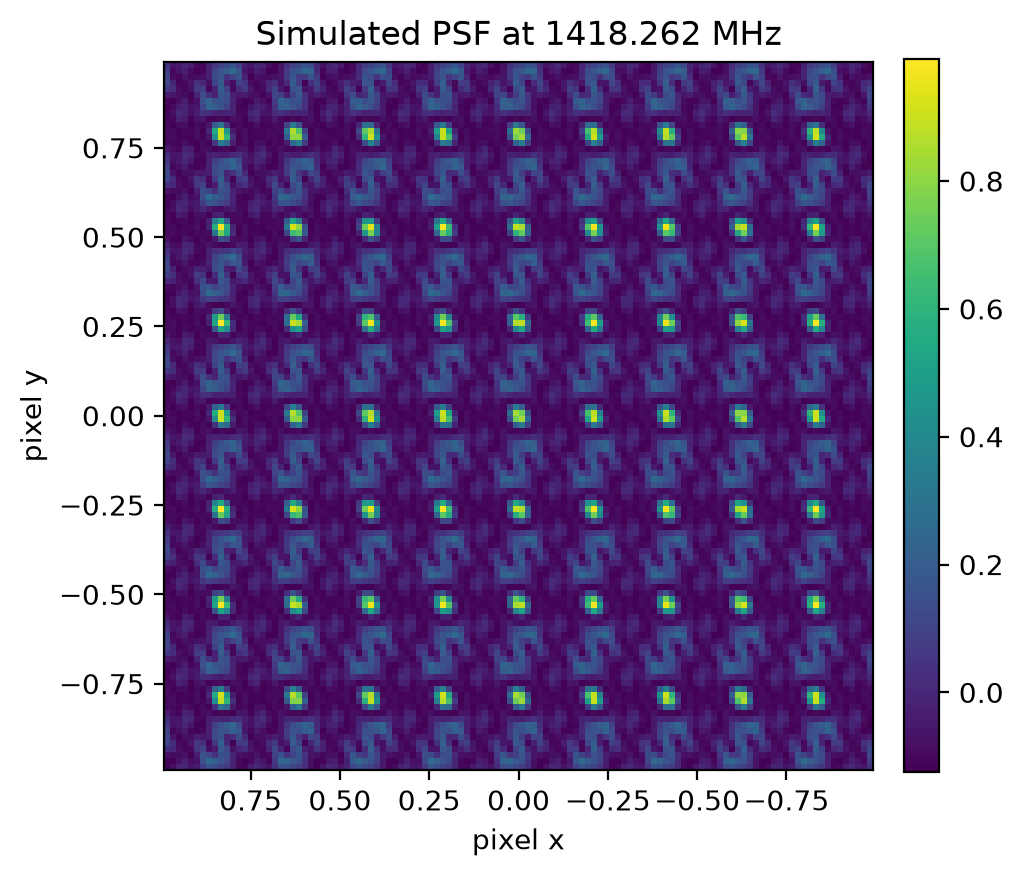

In [15]:
psf, psf_extent = make_image(np.ones_like(acm[obs_num, :, :]), num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im_psf = ax.imshow(psf, extent=psf_extent, origin='lower')

ax.set_title(f"Simulated PSF at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im_psf, ax=ax, fraction=0.046, pad=0.04)
plt.show()


### Perform clean algorithm on simulated data

In [21]:
def hdfig(subplots_def=None, scale=0.5, figsize=(8, 4.5)):
    """ Returns figure according to the LOFAR notebook"""
    fig = plt.figure(figsize=figsize, dpi=scale*1920/8)
    if subplots_def is None:
        return fig
    else:
        return fig, fig.subplots(*subplots_def)
    
def gaussian(height, center_x, center_y, width_x, width_y):
    """Returns a gaussian function with the given parameters"""
    width_x = float(width_x)
    width_y = float(width_y)
    return lambda x,y: height*np.exp(
                -(((center_x-x)/width_x)**2+((center_y-y)/width_y)**2)/2)

def moments(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution by calculating its
    moments """
    total = data.sum()
    X, Y = np.indices(data.shape)
    x = (X*data).sum()/total
    y = (Y*data).sum()/total
    col = data[:, int(y)]
    width_x = np.sqrt(np.abs((np.arange(col.size)-x)**2*col).sum()/col.sum())
    row = data[int(x), :]
    width_y = np.sqrt(np.abs((np.arange(row.size)-y)**2*row).sum()/row.sum())
    height = data.max()
    return height, x, y, width_x, width_y

def fitgaussian(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution found by a fit"""
    params = moments(data)
    errorfunction = lambda p: np.ravel(gaussian(*p)(*np.indices(data.shape)) -
                                 data)
    p, success = scipy.optimize.leastsq(errorfunction, params)
    return p

def subtraction(img_I, psf, gamma, model_image, max_strength_allowed, start_progress):
    """Returns the image with subtracted psf, the new maxiumum value and the input model image with the found brightest point subtracted"""
# function to subract the psf centred around the brightest point in the image

    max_strength = max(img_I.reshape(75*75)) # determine value of brightest pixel
    max_pos = np.where(img_I==max_strength)
    model_image[max_pos[0], max_pos[1]] += max_strength # add pixel brightness to model image

    percentage = (max_strength_allowed-max_strength)/start_progress # progress attempt
    if percentage*100 % 10 == 0:
        print(f"{percentage:.0%}")


    psf_sub = psf * max_strength * gamma # multiply dirty beam with max strength and gamma factor
    shift_psf = ndimage.shift(psf_sub, (-(37-max_pos[0]), -(37-max_pos[1]))) # shift psf centre to brightest pixel

    new_image = img_I-shift_psf # remove psf from image
    
    max_strength = max(new_image.reshape(75*75)) # calculate new maximum
    return {
        "new_pic" : new_image,
        "max_value" : max_strength,
        "model_image" : model_image,

    }


In [22]:
max_strength = max(img.reshape(num_pix**2)) # starting maximum value of the image
max_allowed = 0.5*1e6 # set this to the maximum you want the cleaner to go to 
new_image = img.copy()
model_image = np.zeros_like(img)
start = max_allowed-max_strength

gamma = 0.5 # set this to the needed gamma parameter for cleaning

while max_strength>max_allowed: # cleaning loop runs until the brightest point in the image is less bright than the set max_allowed
    info = subtraction(new_image, psf, gamma, model_image, max_allowed, start)
    new_image = info["new_pic"] 
    max_strength = info["max_value"]
    model_image = info["model_image"]

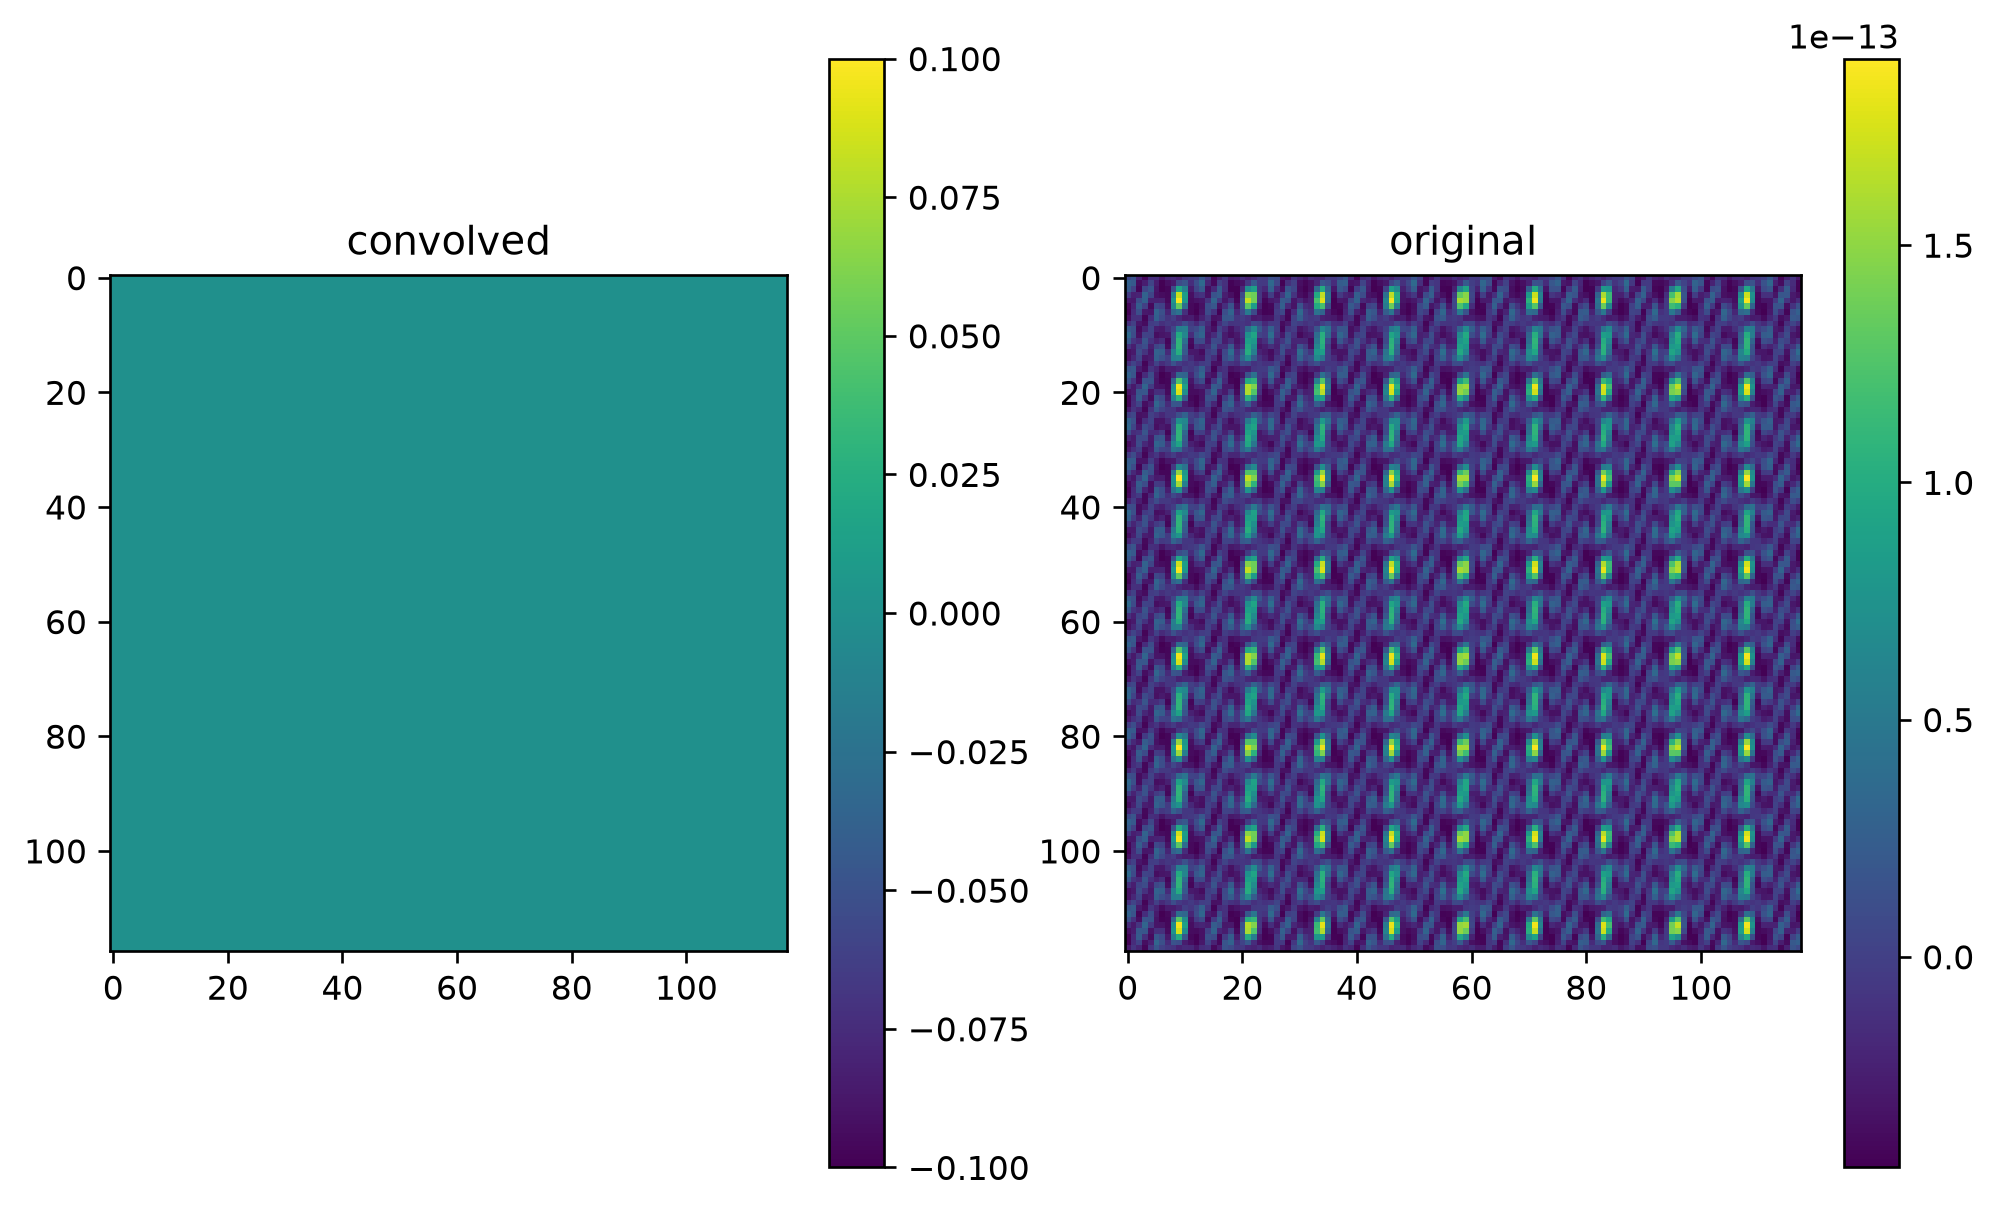

In [23]:
params = fitgaussian(psf)
fit = gaussian(*params)
clean_beam = fit(*np.indices(psf.shape))

convolved_image = scipy.signal.fftconvolve(model_image, clean_beam, mode = "same")

fig, (ax_xx, ax_yy) = hdfig((1,2), figsize=(10,6))
mp_xx = ax_xx.imshow(convolved_image)
ax_xx.set_title("convolved")
mp_yy = ax_yy.imshow(img)
ax_yy.set_title("original")

fig.colorbar(mp_xx, ax=ax_xx)
fig.colorbar(mp_yy, ax=ax_yy)

### Simulate time delays

In [ ]:
def add_delay_errors(acm, frequency, delay_rms_ns, seed=None):
    freq = frequency.to(u.Hz)
    
    n_ant = acm.shape[0]

    # Independent delay error for each antenna (seconds)
    delays = np.random.normal(0, delay_rms_ns *1e-9, n_ant)

    # Delay difference for each antenna pair
    delay_matrix = delays[None, :] - delays[:, None]

    # Convert delay errors to phase errors
    phase_errors = 2 * np.pi * freq * delay_matrix

    # Apply phase errors to the visibility matrix
    acm_corrupted = acm * np.exp(1j * phase_errors.value)

    return acm_corrupted, delays

In [ ]:
delay_errors = [0, 0.1, 0.5, 1, 2, 5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, delay_ns in zip(axes.flat, delay_errors):

    acm_test, delays = add_delay_errors(acm, f, delay_ns)

    img, extent = make_image(acm_test, num_pix, uv, f)

    im = ax.imshow(img, origin="lower", extent=extent)

    ax.set_title(f"Delay RMS = {delay_ns} ns")
    ax.set_xlabel("l [rad]")
    ax.set_ylabel("m [rad]")

    fig.colorbar(im, ax=ax)

plt.show()
